<a href="https://colab.research.google.com/github/ancestor9/2026_Fall_Learning-Langchain-AI-Agent/blob/main/excercise/Agent.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## **Agent**
- **An agent is a model calling tools in a loop until a given task is complete.**

>> [Agent = Model + Harness](https://docs.langchain.com/oss/python/langchain/agents)

>>> The job of a harness: get the model the right context at the right time for the given task.

In [4]:
!pip install -q langchain-google-genai

import os
from google.colab import userdata

# Colab 비밀 키에서 GOOGLE_API_KEY를 가져와 환경 변수로 설정합니다.
try:
    os.environ["GOOGLE_API_KEY"] = userdata.get("GOOGLE_API_KEY")
except Exception as e:
    print("경고: Colab Secrets에서 GOOGLE_API_KEY를 설정했는지 확인해 주세요.")

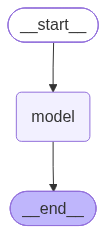

In [8]:
from langchain.agents import create_agent
tools =[]
agent = create_agent(model="google_genai:gemini-3.6-flash", tools=tools)
agent

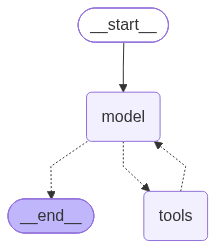

In [9]:
from langchain.tools import tool

@tool
def search(query: str) -> str:
    """Search for information."""
    return f"Results for: {query}"


agent = create_agent(model="google_genai:gemini-3.6-flash", tools=[search])
agent

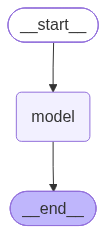

In [11]:
agent = create_agent(
    model="google_genai:gemini-3.6-flash",
    tools=tools,
    system_prompt="You are a helpful assistant. Be concise and accurate.",
)

agent

In [13]:
from pydantic import BaseModel

class Answer(BaseModel):
    summary: str
    confidence: float


agent = create_agent(model="google_genai:gemini-3.6-flash",
                     tools=tools,
                     response_format=Answer)

result = agent.invoke({"messages": [{"role": "user", "content": "Summarize AI trends"}]})
result

{'messages': [HumanMessage(content='Summarize AI trends', additional_kwargs={}, response_metadata={}, id='68c02db6-7975-45be-8532-135a197c7453'),
  AIMessage(content=[{'type': 'text', 'text': '{"summary":"Key AI trends include the rapid adoption of multimodal models capable of processing text, audio, and video simultaneously; the rise of autonomous AI agents for complex task execution; increasing deployment of small, cost-effective language models (SLMs) for edge devices; and a heightened focus on enterprise-grade security, governance, and energy efficiency.","confidence":0.92}', 'extras': {'signature': 'EpYNCpMNAWkUfROUwUfubbPBJZA04S/QMoSoyTvwQCl8zBrnQ97g5RceZgoGdAKFGVZbq/mnKE4cWJZpdLrIyNoyaFE39U5bYJat2akFFOcVGaOp1rTlZUIAZ23SHQiULa/1RlIViRGCaXC8eZbC2qd48LoNQXY8UVcNxz78nfmqrmIXQSXas++5tn0JllvT+BFUDmQSfz1jx+tUY+YfZk07EB3M9Dm/Y85yhKMkmWmWtC9Cj0oMcazCnG0NT/T7A3VIlsXI6h9GRRAKgnAoqfhvJHL6H9Kxp8yUPMEj72F1xgv61FCi0X3KZZ1WOOJDuCGPC3mKCBogDsBryQH2vlveTcy8i2wSK5O9L4ukUh+ZSiMvqncJ/ovbNPN6O1TnBm+j

In [14]:
result["structured_response"]  # Answer(summary=..., confidence=...)

Answer(summary='Key AI trends include the rapid adoption of multimodal models capable of processing text, audio, and video simultaneously; the rise of autonomous AI agents for complex task execution; increasing deployment of small, cost-effective language models (SLMs) for edge devices; and a heightened focus on enterprise-grade security, governance, and energy efficiency.', confidence=0.92)

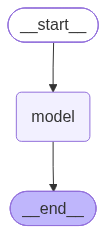

In [15]:
from langchain.agents import AgentState

class MyState(AgentState):
    user_id: str
    call_count: int


agent = create_agent(
    model="google_genai:gemini-3.6-flash",
    tools=[],
    state_schema=MyState,
)
agent

In [16]:
from langchain_core.utils.uuid import uuid7
from langgraph.checkpoint.memory import InMemorySaver

agent = create_agent(
    model="google_genai:gemini-3.6-flash",
    tools=[],
    checkpointer=InMemorySaver(),
)

config = {"configurable": {"thread_id": str(uuid7())}}

result = agent.invoke(
    {"messages": [{"role": "user", "content": "What's the weather in San Francisco?"}]},
    config=config,
)

result

{'messages': [HumanMessage(content="What's the weather in San Francisco?", additional_kwargs={}, response_metadata={}, id='c384b1bd-8b83-47ff-a9bb-5c090c2fd7be'),
  AIMessage(content=[{'type': 'text', 'text': 'I don\'t have access to real-time information, so I can\'t give you the exact current weather for San Francisco right now. \n\nTo get the most accurate, live conditions, you can check:\n* **Google Search:** Type "San Francisco weather" into your browser.\n* **Weather Apps:** Apple Weather, Weather Underground, or The Weather Channel app.\n* **National Weather Service:** Visit [weather.gov](https://www.weather.gov).', 'extras': {'signature': 'EvwHCvkHAWkUfROPRm+JV7HDpTLV5ZsaA9+8eJzCECcjqtnaNQymIH3kJ7Re6uFfAgzAeLmFwCI3ORXl6/EWswiAGs9yquBFZP5Et44EcqLmSytOJ8O6W3v6IcFzOjS9tF9q2CnlHQfM5eCWpENBofDUVwdRMPw+IAZFJaOb+OUgJgapqzvUSe70732D8epsWcqkzRIspdOcUgm6INp0Sjo4U29zh9G4pHZdqbUJfp+0rm12m64tidIl54OHStpnEis3HAcoOGDZDupQTGLoLneGvzhn7+L0CLxcbt0Slu1RgJGzjcAuEYE+xszmaNR7E5YFLWC2aSiv/3j8gd7gBKHA

In [ ]:
uuid7()

In [17]:
# A follow-up turn on the same conversation: reuse the same thread_id to keep history
result = agent.invoke(
    {"messages": [{"role": "user", "content": "What about tomorrow?"}]},
    config=config,
)

result

{'messages': [HumanMessage(content="What's the weather in San Francisco?", additional_kwargs={}, response_metadata={}, id='c384b1bd-8b83-47ff-a9bb-5c090c2fd7be'),
  AIMessage(content=[{'type': 'text', 'text': 'I don\'t have access to real-time information, so I can\'t give you the exact current weather for San Francisco right now. \n\nTo get the most accurate, live conditions, you can check:\n* **Google Search:** Type "San Francisco weather" into your browser.\n* **Weather Apps:** Apple Weather, Weather Underground, or The Weather Channel app.\n* **National Weather Service:** Visit [weather.gov](https://www.weather.gov).', 'extras': {'signature': 'EvwHCvkHAWkUfROPRm+JV7HDpTLV5ZsaA9+8eJzCECcjqtnaNQymIH3kJ7Re6uFfAgzAeLmFwCI3ORXl6/EWswiAGs9yquBFZP5Et44EcqLmSytOJ8O6W3v6IcFzOjS9tF9q2CnlHQfM5eCWpENBofDUVwdRMPw+IAZFJaOb+OUgJgapqzvUSe70732D8epsWcqkzRIspdOcUgm6INp0Sjo4U29zh9G4pHZdqbUJfp+0rm12m64tidIl54OHStpnEis3HAcoOGDZDupQTGLoLneGvzhn7+L0CLxcbt0Slu1RgJGzjcAuEYE+xszmaNR7E5YFLWC2aSiv/3j8gd7gBKHA